# 1、流式调用
invoke 和 stream 有什么区别？
invoke() ：同步调用，在模型输出完成后一次性获取响应，对于输出文本很长的场景，用户体验
不好。
stream() ：流式调用，实时返回响应片段。调用后，返回一个 迭代器(iterator) ，可以通过循环
来实时处理每一个新生成的chunk内容块。
注意：流式输出依赖于模型供应商对于流式输出的支持。

stream()方式的优点：
响应速度更快 — 用户不必等待完整输出
交互体验更流畅 — 尤其在长文本或复杂推理场景下
可实时展示模型思考过程

In [4]:
import os
from pydantic import SecretStr
from dotenv import load_dotenv
from langchain_openrouter import ChatOpenRouter

# 1、读取.env配置文件中的信息。相关的环境变量以.env文件优先
load_dotenv(verbose=True)
OPENROUTER_API_KEY=SecretStr(os.getenv("OPENROUTER_API_KEY")or"")

# 2、模型的初始化
model=ChatOpenRouter(
    model="poolside/laguna-s-2.1:free",
    api_key=OPENROUTER_API_KEY,

)
# 3、模型的调用
for chunk in model.stream("帮我解释一下什么是人工智能？"):
    print(chunk.text,end="",flush=True)

**人工智能 (Artificial Intelligence, AI)** 是指通过计算机系统模拟人类智能行为的技术和方法，使机器能够执行通常需要人类智能的任务，如学习、推理、问题解决、感知、理解语言等。

### 核心概念
1. **学习 (Learning)**：通过数据训练模型，自动提升性能（如机器学习、深度学习）。
2. **推理 (Reasoning)**：使用逻辑规则或模式识别进行决策和推断。
3. **感知 (Perception)**：通过传感器（如摄像头、麢达）理解环境（如计算机视觉、语音识别）。
4. **语言理解 (NLP)**：处理和生成自然语言（如聊天机器人、翻译系统）。

### 主要类型
- **狭人工智能 (Narrow AI)**：专注于特定任务（如推荐算法、图像识别），当前广泛应用。
- **通用人工智能 (AGI)**：具备人类一般智能，尚处于研究阶段。
- **监督学习**：使用标记数据训练模型（如分类、回归）。
- **无监督学习**：从无标记数据中发现隐藏结构（如聚类）。
- **强化学习**：通过试错获得最大奖励（如游戏AI、机器人控制）。

### 应用实例
- **生活**：语音助手（Siri），推荐系统（Netflix）。
- **医疗**：疾病诊断、药物发现。
- **交通**：自动驾驶汽车。
- **金融**：欺诈检测、算法交易。

### 实现技术
- **算法**：决策树、神经网络、支持向量机。
- **数据**：海量数据是训练模型的基础。
- **算力**：GPU等高性能硬件加速计算。

人工智能的发展依赖于数据、算法和计算资源的协同，但其应用需考虑伦理和隐私问题。

# 2、批量调用(batch)
举例1：一次性接收所有的响应

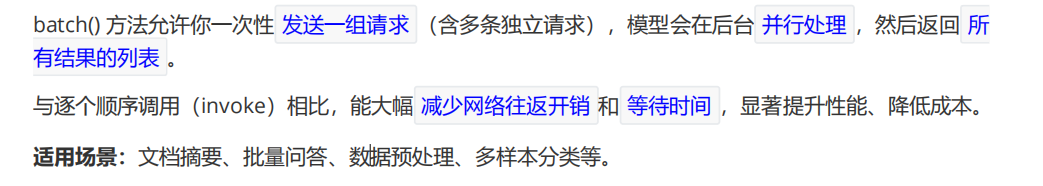

In [5]:
messages = [
"你好，你是谁？",
"2 + 3 * 5 = ?",
"中国首都在哪里？"
]
responses = model.batch(messages)
for response in responses:
    print(response)

content='你好！我是一位人工智能助手，叫做 小度。我是由度盘（Xiaodu AI）团队开发的，主要用于提供各类信息和服务。我的目标是帮助用户解决问题、提供支持，让生活更加便利。请问有什么我能够帮你的吗？' additional_kwargs={} response_metadata={'model_name': 'poolside/laguna-s-2.1:free', 'id': 'gen-1792031910-QgbVVnXIYJm1wzSGhY5l', 'created': 1792031910, 'object': 'chat.completion', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'openrouter'} id='lc_run--01a13d6c-dc2c-7cc0-8934-e60a479f6257-0' tool_calls=[] invalid_tool_calls=[] usage_metadata={'input_tokens': 51, 'output_tokens': 74, 'total_tokens': 125, 'input_token_details': {'cache_read': 32, 'cache_creation': 0}, 'output_token_details': {'reasoning': 0}}
content='The calculation follows the order of operations, where multiplication is performed before addition:\n\n1. **Multiply** 3 by 5:  \n   \\( 3 \\times 5 = 15 \\)\n   \n2. **Add** the result to 2:  \n   \\( 2 + 15 = 17 \\)\n\n**Answer:** \\( \\boxed{17} \\)' additional_kwargs={'reasoning_content': "Okay, let's see. I need to calculate 2 plus 3 multiplied by 5

举例2：按照完成的顺序接受响应

In [3]:
messages = [
"你好，你是谁？",
"2 + 3 * 5 = ?",
"中国首都在哪里？"
]
responses = model.batch_as_completed(messages)
for response in responses:
    print(response)

(2, AIMessage(content='中国的首都是**北京**。', additional_kwargs={}, response_metadata={'model_name': 'google/gemma-4-26b-a4b-it:free', 'id': 'gen-1791709089-Ox6UpvJkHWug2UXWORYT', 'created': 1791709089, 'object': 'chat.completion', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'openrouter'}, id='lc_run--01a12a2f-05c6-73f1-97ad-fc5d204cda41-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 6, 'output_tokens': 7, 'total_tokens': 13, 'input_token_details': {'cache_read': 0, 'cache_creation': 0}, 'output_token_details': {'reasoning': 0}}))
(0, AIMessage(content='你好！我是 Gemma 4，是由 Google DeepMind 开发的大语言模型。我是一个开放权重模型，能够理解和处理文本与图像信息。很高兴为你提供帮助！', additional_kwargs={}, response_metadata={'model_name': 'google/gemma-4-26b-a4b-it:free', 'id': 'gen-1791709089-POtTmCf4iHD92QzniZI4', 'created': 1791709089, 'object': 'chat.completion', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'openrouter'}, id='lc_run--01a12a2f-05b0-7110-ad43-82bb2499ae09-0', tool_ca

举例3 性能对比

In [4]:
# 准备多个输入
inputs = [
"翻译成英文：春天来了",
"翻译成英文：夏天很热",
"翻译成英文：秋天落叶",
"翻译成英文：冬天下雪"
]
# ✅ 批量调用（高效）
import time

start = time.time()# 记录“现在”是几点几分几秒（时间戳）
responses = model.batch(inputs)
batch_time = time.time() - start
print("批量调用结果：")
for i, response in enumerate(responses):
    print(f"{i+1}. {response.content}")
print(f"耗时: {batch_time:.2f}秒\n")

批量调用结果：
1. “春天来了”最常用的翻译是：

**1. Spring is coming.**
（强调春天正在到来，或者即将到来。）

**2. Spring has come.**
（强调春天已经到了，或者春天已经降临。）

**3. Spring is here.**
（最地道、最常用的口语表达，意为“春天到了”。）

**根据语境选择：**
* 如果你想表达一种**期待感**：*Spring is on its way.*
* 如果你想表达一种**文学/诗意**的感觉：*Spring has arrived.*
2. 根据语境，有以下几种翻译方式：

1. **最常用/最直接：**
   **It is hot in summer.** 
   (这是最标准的陈述句。)

2. **强调“夏天很热”这个事实：**
   **Summer is hot.**
   (比较简洁，常用于描述季节的特征。)

3. **口语/强调程度（夏天特别热）：**
   **It's very hot in summer.** (夏天非常热。)
   **The summer is scorching.** (夏天酷热难耐。)

**总结建议：**
如果你只是想简单表达这个意思，用 **"It is hot in summer"** 或 **"Summer is hot"** 即可。
3. 根据你想表达的语境，有以下几种翻译方式：

1. **最常用的表达（名词短语）：**
   * **Fallen leaves in autumn** (最标准、最完整的说法)
   * **Autumn fallen leaves** (较简洁)

2. **文学/诗意点表达（强调“落叶”这个意象）：**
   * **Falling leaves in autumn** (强调“正在飘落”的动态感)
   * **Autumnal leaves** (比较书面、优美的表达)

3. **作为动作（动词短语）：**
   * **Leaves falling in autumn** (秋天落叶的过程)

**总结建议：**
* 如果只是想描述**“地上的落叶”**，用 **Fallen leaves**。
* 如果是想描述**“正在落叶的景象”**，用 **Falling leav